# Computer lab 4: stochastic optimization

**Mathematical Optimization, VU Amsterdam, 2026–27.**

If time is limited, work through 1(a), 1(d), 1(f) and 1(g), then 3(a)–(c)
and Exercise 4. Return to the other parts of Exercise 1 and the newsvendor
in Exercise 2 afterward. Exercise 2(e) reproduces the SAA plot in L8.

Fill in the marked sections as you work. Remove the `NotImplementedError`
line after completing each function.

The examples draw on the
[MO-book companion notebooks](https://mobook.github.io/MO-book/intro.html)
([MIT license](https://github.com/mobook/MO-book/blob/ef77f6b9768453c300d5d97e42e89fce1f5e832e/LICENSE)).

## Setup

Run the next two cells to prepare Pyomo and HiGHS. If prompted to restart
the session, restart it and rerun both cells.
See the [course setup guide](https://github.com/alessandrozocca/MO2026#computer-lab-setup)
for help.

Use `solve_and_load(model, lp_solver)` for each solve. It checks for an
optimal result before loading the solution.

In [1]:
#@title Prepare course helpers and solvers
import hashlib
import os
from pathlib import Path
import sys
import time
import types
from urllib.error import HTTPError, URLError
from urllib.request import urlopen

SETUP_COMMIT = '425c3f0af23e082c276df85fcde556538cc2abef'
SETUP_SHA256 = "f742478c6eaf5c5db82f4ce69b47a2adcf6f920765d88c3e7eb1b1ab72e66d28"
local_repo = os.environ.get("MO2026_REPO")
if local_repo:
    setup_location = str(Path(local_repo).expanduser() / "lab_setup.py")
    setup_source = Path(setup_location).read_bytes()
else:
    setup_location = f"https://raw.githubusercontent.com/alessandrozocca/MO2026/{SETUP_COMMIT}/lab_setup.py"
    for attempt in range(3):
        try:
            with urlopen(setup_location, timeout=30) as response:
                setup_source = response.read()
            break
        except (URLError, TimeoutError, ConnectionError) as error:
            if (isinstance(error, HTTPError) and error.code not in (408, 429, 500, 502, 503, 504)) or attempt == 2:
                raise
            time.sleep(0.5 * (attempt + 1))
    if hashlib.sha256(setup_source).hexdigest() != SETUP_SHA256:
        raise RuntimeError("Course setup checksum mismatch; the downloaded code was not executed.")

lab_setup = types.ModuleType("mo2026_lab_setup")
lab_setup.__file__ = setup_location
sys.modules[lab_setup.__name__] = lab_setup
exec(compile(setup_source, setup_location, "exec"), lab_setup.__dict__)
if local_repo and lab_setup.API_VERSION != 1:
    raise RuntimeError("This notebook requires course setup API 1.")
lab = lab_setup.setup(week=4, check=False, verbose=True)
solve_and_load = lab_setup.solve_and_load
lp_solver = lab.lp_solver

Week 4 ready: Pyomo 6.10.1; HiGHS 1.15.1.


In [2]:
%matplotlib inline
import math

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyomo.environ as pyo
from IPython.display import display
from scipy.stats import norm, pareto, uniform, weibull_min

# Use a zero relative MIP gap to report a proven optimum, within solver tolerances.
lp_solver.options['mip_rel_gap'] = 0.0

## Exercise 1: the farmer's problem and its variants

A farmer can plant up to 500 acres of wheat, corn and sugar beets before
the weather is known. The three weather scenarios are equally likely.
Purchases and sales can respond to the weather.

| Crop | Planting cost (€/acre) | Feed needed (tons) | Sale price (€/ton) | Purchase price (€/ton) |
|:---|---:|---:|---:|---:|
| Wheat | 150 | 200 | 170 | 238 |
| Corn | 230 | 240 | 150 | 210 |
| Sugar beets | 260 | 0 | 36 up to 6,000 tons, 10 above | Not purchased |

| Weather | Wheat yield | Corn yield | Beet yield |
|:---|---:|---:|---:|
| Good (`H`) | 3 | 3.6 | 24 |
| Average (`M`) | 2.5 | 3 | 20 |
| Bad (`L`) | 2 | 2.4 | 16 |

Yields are in tons per acre. The farmer can buy wheat or corn to cover a
feed shortfall and can leave some of the harvest unused.
The [MO-book farmer notebook](https://mobook.github.io/MO-book/notebooks/10/04-farmer-problem.html)
uses the same base data.

**(a)** Complete the scenario balance and beet-quota rows in `farmer_model`.
Solve the extensive form and report the planting, scenario profits and
expected profit. Identify the first-stage and recourse decisions. Why must
planting be shared across scenarios? Give a feasible trade in each scenario
for an arbitrary feasible planting.

In [3]:
CROPS = ['W', 'C', 'S']
crop_names = {'W': 'Wheat', 'C': 'Corn', 'S': 'Sugar beets'}
planting_cost = {'W': 150.0, 'C': 230.0, 'S': 260.0}
mean_yield = {'W': 2.5, 'C': 3.0, 'S': 20.0}
feed = {'W': 200.0, 'C': 240.0}
sale_price = {'W': 170.0, 'C': 150.0}
purchase_price = {'W': 238.0, 'C': 210.0}
weather = {'H': 1.2, 'M': 1.0, 'L': 0.8}

In [4]:
def farmer_model(yield_factors=None, price_factors=None, probabilities=None):
    factors = dict(weather if yield_factors is None else yield_factors)
    if not factors or any(not np.isfinite(v) or v < 0 for v in factors.values()):
        raise ValueError('Supply nonnegative yields for at least one scenario.')
    prices = {s: 1.0 for s in factors} if price_factors is None else dict(price_factors)
    weights = {s: 1.0 for s in factors} if probabilities is None else dict(probabilities)
    if set(prices) != set(factors) or set(weights) != set(factors):
        raise ValueError('Scenario labels must agree.')
    if any(not np.isfinite(v) or v <= 0 for v in prices.values()):
        raise ValueError('Price factors must be positive.')
    if any(not np.isfinite(v) or v < 0 for v in weights.values()) or sum(weights.values()) <= 0:
        raise ValueError('Scenario weights must be nonnegative with a positive sum.')
    total_weight = sum(weights.values())

    m = pyo.ConcreteModel('Farmer')
    m.CROPS = pyo.Set(initialize=CROPS)
    m.FEED = pyo.Set(initialize=['W', 'C'])
    m.SCENARIOS = pyo.Set(initialize=list(factors))
    m.probability = pyo.Param(m.SCENARIOS, initialize={s: weights[s] / total_weight for s in factors})
    m.plant = pyo.Var(m.CROPS, domain=pyo.NonNegativeReals, bounds=(0, 500))
    m.land = pyo.Constraint(expr=sum(m.plant[c] for c in m.CROPS) <= 500)
    m.buy = pyo.Var(m.FEED, m.SCENARIOS, domain=pyo.NonNegativeReals)
    m.sell = pyo.Var(m.CROPS, m.SCENARIOS, domain=pyo.NonNegativeReals)
    m.sell_extra = pyo.Var(m.SCENARIOS, domain=pyo.NonNegativeReals)

    # BEGIN FARMER ROWS
    @m.Constraint(m.FEED, m.SCENARIOS)
    def feed_balance(m, c, s):
        return mean_yield[c] * factors[s] * m.plant[c] + m.buy[c, s] - m.sell[c, s] >= feed[c]

    @m.Constraint(m.SCENARIOS)
    def beet_balance(m, s):
        return m.sell['S', s] + m.sell_extra[s] <= mean_yield['S'] * factors[s] * m.plant['S']

    @m.Constraint(m.SCENARIOS)
    def beet_quota(m, s):
        return m.sell['S', s] <= 6000
    # END FARMER ROWS

    m.first_stage_profit = pyo.Expression(expr=-sum(planting_cost[c] * m.plant[c] for c in m.CROPS))

    @m.Expression(m.SCENARIOS)
    def recourse_profit(m, s):
        return (sum(prices[s] * (sale_price[c] * m.sell[c, s] - purchase_price[c] * m.buy[c, s])
                    for c in m.FEED)
                + 36 * m.sell['S', s] + 10 * m.sell_extra[s])

    @m.Expression(m.SCENARIOS)
    def scenario_profit(m, s):
        return m.first_stage_profit + m.recourse_profit[s]

    m.total_expected_profit = pyo.Objective(
        expr=sum(m.probability[s] * m.scenario_profit[s] for s in m.SCENARIOS),
        sense=pyo.maximize,
    )
    return m

In [5]:
def planting_plan(model):
    return pd.Series({c: pyo.value(model.plant[c]) for c in model.CROPS}, name='Acres')


def farm_report(model):
    display(planting_plan(model).rename(index=crop_names).round(2).to_frame())
    profits = pd.Series({s: pyo.value(model.scenario_profit[s]) for s in model.SCENARIOS},
                        name='Scenario profit (€)')
    display(profits.round(2).to_frame())
    print(f'Expected profit: €{pyo.value(model.total_expected_profit):,.2f}')

In [6]:
farmer_rp = farmer_model()
solve_and_load(farmer_rp, lp_solver)
farmer_optimum = pyo.value(farmer_rp.total_expected_profit)
farm_report(farmer_rp)

,Acres
Wheat,170.0
Corn,80.0
Sugar beets,250.0


,Scenario profit (€)
H,167000.0
M,109350.0
L,48820.0


Expected profit: €108,390.00


The optimum plants $(170,80,250)$ acres, with expected profit €108,390.
Planting must be fixed before the weather is known. Purchases and sales
can vary by scenario.

For any feasible planting, buy wheat and corn to cover shortfalls, sell
their surpluses, and sell the beets at the quota price up to 6,000 tons
and the lower price above that. This proves relatively complete recourse
and satisfies the balance equalities used in L8. The lab allows unused
harvest. Since all sale prices are positive, selling any unused surplus
improves profit, so the two formulations have the same optimal trading
profit for each fixed planting and scenario.

The yield terms move to the right-hand side once planting is fixed. The
coefficients on purchases and sales stay the same across scenarios, so
the base model has fixed recourse.

**(b)** Wheat and corn prices fall by 10% in good weather and rise by 10% in
bad weather. Apply the changes to both purchase and sale prices. Beet prices
remain fixed. Modify the extensive form, solve it, and compare with (a).

| Weather | Wheat sale | Corn sale | Wheat purchase | Corn purchase |
|:---|---:|---:|---:|---:|
| Good | 153 | 135 | 214.2 | 189 |
| Average | 170 | 150 | 238 | 210 |
| Bad | 187 | 165 | 261.8 | 231 |

Prices are in euros per ton. The `price_factors` argument applies only to
wheat and corn.

In [7]:
farmer_prices = farmer_model(price_factors={'H': 0.9, 'M': 1.0, 'L': 1.1})
solve_and_load(farmer_prices, lp_solver)
farm_report(farmer_prices)

,Acres
Wheat,170.0
Corn,80.0
Sugar beets,250.0


,Scenario profit (€)
H,161010.0
M,109350.0
L,50192.0


Expected profit: €106,850.67


The planting remains $(170,80,250)$, but expected profit falls by €1,539.33
to €106,850.67. Relative to (a), good-weather profit falls by €5,990,
average-weather profit is unchanged, and bad-weather profit rises by €1,372.
In bad weather, the increase in wheat-sale revenue (€2,380) more than offsets
the additional corn-purchase cost (€1,008). The expected loss therefore comes
from the good-weather price reduction, partly offset by the bad-weather gain.

**(c)** Return to the fixed prices in (a). The farm has four fields of 185,
145, 105 and 65 acres. Each field can be left idle or planted with a single
crop. Add binary field-assignment variables to a model returned by
`farmer_model` and link them to the crop acreages. Solve and report the
field assignments, crop acreages and expected profit.

In [8]:
field_sizes = {1: 185, 2: 145, 3: 105, 4: 65}
farmer_fields = farmer_model()
farmer_fields.FIELDS = pyo.Set(initialize=list(field_sizes))
farmer_fields.assign = pyo.Var(farmer_fields.FIELDS, farmer_fields.CROPS, domain=pyo.Binary)

@farmer_fields.Constraint(farmer_fields.FIELDS)
def field_select(m, f):
    return sum(m.assign[f, c] for c in m.CROPS) <= 1

@farmer_fields.Constraint(farmer_fields.CROPS)
def assigned_acres(m, c):
    return m.plant[c] == sum(field_sizes[f] * m.assign[f, c] for f in m.FIELDS)

solve_and_load(farmer_fields, lp_solver)
field_assignment = pd.Series({
    f: next((crop_names[c] for c in CROPS if pyo.value(farmer_fields.assign[f, c]) > 0.5), 'Idle')
    for f in field_sizes
}, name='Crop')
display(field_assignment.to_frame().rename_axis('Field'))
farm_report(farmer_fields)

,Crop
Field,
1,Sugar beets
2,Wheat
3,Corn
4,Sugar beets


,Acres
Wheat,145.0
Corn,105.0
Sugar beets,250.0


,Scenario profit (€)
H,165750.0
M,107975.0
L,50200.0


Expected profit: €107,975.00


Fields 1 and 4 grow sugar beets, field 2 grows wheat, and field 3 grows corn.
The crop acreages are $(145,105,250)$ and expected profit is €107,975.
The €415 loss relative to (a) is the cost of restricting planting to whole fields.

**(d)** Find the planting that maximizes worst-case profit. For any fixed
planting, higher yields cannot reduce optimal trading profit at the prices
in (a), so the worst case occurs in bad weather.

Solve the bad-weather LP. Fix its three acreages at full precision in the
three-scenario model and reoptimize purchases and sales. How much expected
profit does this planting give up relative to (a)?

In [9]:
farmer_worst = farmer_model(yield_factors={'L': 0.8})
solve_and_load(farmer_worst, lp_solver)
worst_plan = planting_plan(farmer_worst)
farmer_worst_evaluation = farmer_model()
for c in CROPS:
    farmer_worst_evaluation.plant[c].fix(float(worst_plan[c]))
solve_and_load(farmer_worst_evaluation, lp_solver)
farm_report(farmer_worst_evaluation)
worst_expected_profit = pyo.value(farmer_worst_evaluation.total_expected_profit)
print(f'Optimal bad-weather profit: €{pyo.value(farmer_worst.total_expected_profit):,.2f}')
print(f'Expected-profit loss: €{farmer_optimum - worst_expected_profit:,.2f}')

,Acres
Wheat,100.0
Corn,25.0
Sugar beets,375.0


,Scenario profit (€)
H,113250.0
M,86600.0
L,59950.0


Expected profit: €86,600.00
Optimal bad-weather profit: €59,950.00
Expected-profit loss: €21,790.00


The maximin planting is $(100,25,375)$, with worst-case profit €59,950.
After reoptimizing trades, its good, average and bad weather profits are
€113,250, €86,600 and €59,950. Expected profit is €86,600, a loss of €21,790.

A maximin solve need not maximize recourse profit in scenarios above the
worst-case floor. The book resolves this by maximizing expected profit while
retaining the optimal floor. Here fixing the planting and reoptimizing its
trades provides the evaluation requested in the question.

**(e)** Use the prices from (a) and maximize expected profit subject to a
profit of at least €58,000 in every scenario. How much expected profit
does this cost relative to (a)?

Repeat for floors of €48,000, €50,000, €52,000, €54,000, €56,000 and €56,800,
and for the optimal bad-weather profit from (d). Plot the expected-profit
loss against the floor, including the €58,000 case, and compare the crop
acreages. The MO-book farmer notebook also uses the €56,800 floor.

,Expected profit (€),Expected-profit loss (€),Wheat,Corn,Sugar beets
Floor (€),,,,,
48000.0,108390.00,0.00,170.00,80.00,250.00
50000.0,108291.67,98.33,155.95,94.05,250.00
52000.0,107976.19,413.81,138.10,100.00,261.90
54000.0,107611.11,778.89,122.22,100.00,277.78
56000.0,107246.03,1143.97,106.35,100.00,293.65
56800.0,107100.00,1290.00,100.00,100.00,300.00
58000.0,101176.19,7213.81,100.00,71.43,328.57
59950.0,86600.00,21790.00,100.00,25.00,375.00


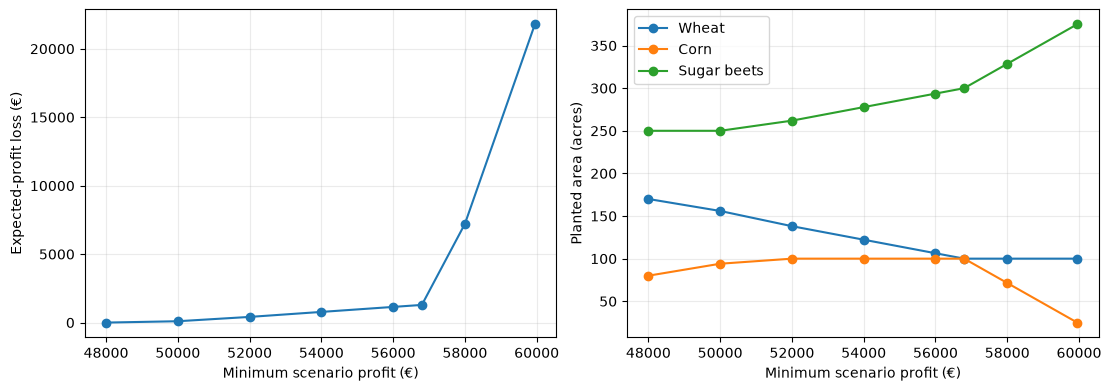

In [10]:
maximin_floor = pyo.value(farmer_worst.total_expected_profit)
frontier_models = {}
frontier_rows = []
for floor in [48000, 50000, 52000, 54000, 56000, 56800, 58000, maximin_floor]:
    model = farmer_model()
    model.profit_floor = pyo.Constraint(model.SCENARIOS,
        rule=lambda m, s: m.scenario_profit[s] >= floor)
    solve_and_load(model, lp_solver)
    frontier_models[floor] = model
    expected = pyo.value(model.total_expected_profit)
    frontier_rows.append({'Floor (€)': floor, 'Expected profit (€)': expected,
                          'Expected-profit loss (€)': farmer_optimum - expected,
                          **{c: pyo.value(model.plant[c]) for c in CROPS}})
farmer_frontier = pd.DataFrame(frontier_rows).set_index('Floor (€)')
display(farmer_frontier.rename(columns=crop_names).round(2))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), layout='constrained')
farmer_frontier['Expected-profit loss (€)'].plot(ax=axes[0], marker='o')
axes[0].set(xlabel='Minimum scenario profit (€)', ylabel='Expected-profit loss (€)')
farmer_frontier[CROPS].rename(columns=crop_names).plot(ax=axes[1], marker='o')
axes[1].set(xlabel='Minimum scenario profit (€)', ylabel='Planted area (acres)')
for ax in axes:
    ax.grid(alpha=0.25)
plt.show()

The unconstrained RP plan already guarantees €48,820, so a €48,000 floor
costs nothing. At €56,800 the planting is $(100,100,300)$ and expected profit
is €107,100, a loss of €1,290. This plan exactly covers both feed requirements
in bad weather and reaches the beet quota in average weather. It is also
the planting in L8's $\operatorname{CVaR}_{1/2}$ example. Here the model
maximizes expected profit subject to a floor in every scenario. L8's model
minimizes average loss in the upper tail.

Above this floor, the solution increases beet acreage beyond 300 and reduces
corn acreage. Additional average-weather beets sell for only €10 per ton,
while the lost corn harvest requires purchases in bad weather. Expected-profit
loss therefore rises more steeply: it is €7,213.81 at a €58,000 floor.
At the maximum floor of €59,950, planting is $(100,25,375)$ and expected
profit is €86,600, recovering (d). The expected-profit loss is €21,790.

**(f)** Turn the calculation in (d) into a function,
`evaluate_planting(plan, yield_factors=None, probabilities=None)`. Fix all
three acreages, reoptimize purchases and sales, and return the net profit
in each scenario and its probability-weighted mean. Include planting costs
in each scenario profit.

Use the expected profit from (a) for RP. Solve the mean-yield problem for
the expected-value (EV) planting and evaluate it on the original three
scenarios to obtain EEV. For the wait-and-see value (WS), optimize planting
and trading separately in each scenario and average the resulting profits.
Order RP, EEV and WS, then compute VSS and EVPI and check their signs.

Use L8's profit convention. For the cost convention, see Sheet 4 Exercise
3(d). Check your function on the planting from (d).

In [11]:
def evaluate_planting(plan, yield_factors=None, probabilities=None):
    if set(plan.keys()) != set(CROPS):
        raise ValueError('Freeze all three crop acreages.')
    values = {c: float(plan[c]) for c in CROPS}
    if any(not np.isfinite(v) or v < 0 for v in values.values()) or sum(values.values()) > 500 + 1e-7:
        raise ValueError('The planting plan must be feasible.')
    model = farmer_model(yield_factors=yield_factors, probabilities=probabilities)
    for c in CROPS:
        model.plant[c].fix(values[c])
    solve_and_load(model, lp_solver)
    profits = pd.Series({s: pyo.value(model.scenario_profit[s]) for s in model.SCENARIOS})
    return {'model': model, 'scenario_profits': profits,
            'expected_profit': pyo.value(model.total_expected_profit)}


farmer_ev = farmer_model(yield_factors={'mean': np.mean(list(weather.values()))})
solve_and_load(farmer_ev, lp_solver)
ev_plan = planting_plan(farmer_ev)
farmer_eev = evaluate_planting(ev_plan)
farmer_ws_models = {}
for s, factor in weather.items():
    model = farmer_model(yield_factors={s: factor})
    solve_and_load(model, lp_solver)
    farmer_ws_models[s] = model

RP = farmer_optimum
EEV = farmer_eev['expected_profit']
WS = sum(pyo.value(m.total_expected_profit) for m in farmer_ws_models.values()) / len(weather)
farmer_benchmarks = pd.Series({'RP': RP, 'EEV': EEV, 'WS': WS,
                               'VSS = RP - EEV': RP - EEV, 'EVPI = WS - RP': WS - RP})
display(ev_plan.rename(index=crop_names).to_frame())
print(f'Mean-data optimum, before evaluation: €{pyo.value(farmer_ev.total_expected_profit):,.2f}')
display(farmer_benchmarks.round(2).to_frame('Profit (€)'))
worst_replay = evaluate_planting(worst_plan)
print(f'Replay of (d): €{worst_replay["expected_profit"]:,.2f}')

,Acres
Wheat,120.0
Corn,80.0
Sugar beets,300.0


Mean-data optimum, before evaluation: €118,600.00


,Profit (€)
RP,108390.00
EEV,107240.00
WS,115405.56
VSS = RP - EEV,1150.00
EVPI = WS - RP,7015.56


Replay of (d): €86,600.00


The mean-yield model chooses $(120,80,300)$ and gives €118,600 at those
yields. Fixing this planting and reoptimizing the trades in all three
scenarios gives EEV of €107,240. The profit benchmarks satisfy

$$
WS=115{,}405.56\ \ge\ RP=108{,}390\ \ge\ EEV=107{,}240.
$$

Thus VSS is €1,150 and EVPI is €7,015.56. Defining cost as negative
profit reverses the ordering and the subtraction order, so EVPI and VSS
have the same values.

**(g) Tail risk of a fixed planting.** Implement the auxiliary-variable LP
from L8 as `cvar_from_losses(losses, alpha)` for equally likely losses and
$0<\alpha<1$. The threshold $\eta$ is unrestricted in sign. Check the LP
against a hand calculation for the losses $(1,2,3,4)$ at $\alpha=0.6$.

Use `evaluate_planting` from (f) on the RP planting from (a) and L8's
planting of $(100,100,300)$ acres of wheat, corn and beets. Take each loss
to be the negative of net profit. For each planting, report the scenario
profits, expected profit and $\operatorname{CVaR}_{1/2}$ of the loss.
Which planting does each criterion favor? By how much does the average
profit over the worst half of the probability mass change?

In [12]:
def cvar_from_losses(losses, alpha):
    values = np.asarray(losses, dtype=float)
    if values.ndim != 1 or values.size == 0 or not np.all(np.isfinite(values)):
        raise ValueError('Supply a nonempty vector of finite losses.')
    if not 0 < alpha < 1:
        raise ValueError('The CVaR level must be strictly between zero and one.')

    m = pyo.ConcreteModel('CVaR of fixed losses')
    m.SCENARIOS = pyo.RangeSet(0, len(values) - 1)
    m.eta = pyo.Var(domain=pyo.Reals)
    m.excess = pyo.Var(m.SCENARIOS, domain=pyo.NonNegativeReals)
    m.tail = pyo.Constraint(m.SCENARIOS,
        rule=lambda m, s: m.excess[s] >= float(values[s]) - m.eta)
    m.cvar = pyo.Objective(
        expr=m.eta + sum(m.excess[s] for s in m.SCENARIOS) / ((1 - alpha) * len(values)),
        sense=pyo.minimize,
    )
    solve_and_load(m, lp_solver)
    return pyo.value(m.cvar)


hand_check = cvar_from_losses([1, 2, 3, 4], 0.6)
assert np.isclose(hand_check, 3.625)
print(f'Losses (1, 2, 3, 4) at alpha = 0.6: {hand_check:.6f}')

risk_plans = {
    'RP': planting_plan(farmer_rp),
    'L8 CVaR plan': {'W': 100, 'C': 100, 'S': 300},
}
risk_rows = []
for name, plan in risk_plans.items():
    result = evaluate_planting(plan)
    profits = result['scenario_profits']
    risk_rows.append({'Plan': name, 'Good (€)': profits['H'],
                      'Average (€)': profits['M'], 'Bad (€)': profits['L'],
                      'Expected profit (€)': result['expected_profit'],
                      'Loss CVaR at 0.5 (€)': cvar_from_losses(-profits, 0.5)})
farmer_risk = pd.DataFrame(risk_rows).set_index('Plan')
display(farmer_risk.round(2))

Losses (1, 2, 3, 4) at alpha = 0.6: 3.625000


,Good (€),Average (€),Bad (€),Expected profit (€),Loss CVaR at 0.5 (€)
Plan,,,,,
RP,167000.0,109350.0,48820.0,108390.0,-68996.67
L8 CVaR plan,147000.0,117500.0,56800.0,107100.0,-77033.33


For the check, $\operatorname{VaR}_{0.6}=3$. The worst 40% consists of all
$0.25$ probability mass at loss 4 and another $0.15$ at loss 3. Thus
$\operatorname{CVaR}_{0.6}=(4\cdot0.25+3\cdot0.15)/0.4=3.625$.

At level $1/2$, take the $1/3$ probability mass at the largest loss and
$1/6$ at the next loss. Expected profit favors RP (€108,390 versus
€107,100). Loss CVaR favors $(100,100,300)$, with about $-77{,}033.33$
euros versus $-68{,}996.67$ for RP. Moving to $(100,100,300)$ raises
the worst-half average profit by €8,036.67 and lowers expected profit by
€1,290. The difference in the tail averages uses full precision.

## Exercise 2: a newsvendor model for seafood inventory

A seafood distribution center buys tuna before observing retailer demand.
The purchase price is $c=10$, the sale price is $p=25$, and the cost of
storing unsold tuna is $h=5$, in euros per ton. For an order $x\ge0$ tons
and demand $z\ge0$ tons, the profit is

$$
f(x,z)=p\min(x,z)-cx-h(x-z)^+.
$$

Use uniform demand on $[50,150]$, Pareto demand with $x_m=50$ and
$\alpha=2$, and Weibull demand with shape $k=2$ and scale $\lambda=113$.
These are the parameters in L8's SAA example. The
[MO-book seafood notebook](https://mobook.github.io/MO-book/notebooks/09/03-seafood-distribution-center.html)
uses the same model with different parameters.

**(a)** Find each optimal order using L7's quantile formula
$x^*=F^{-1}(r)$, where $r=(p-c)/(p+h)$ is the critical ratio. Use the
distribution objects below or implement the inverse CDFs directly. For the
Pareto law, $F^{-1}(q)=50/(1-q)^{1/2}$. Plot the CDFs and mark the optimal
orders.

In [13]:
c, p, h = 10.0, 25.0, 5.0
distributions = {
    'Uniform': uniform(loc=50, scale=100),
    'Pareto': pareto(b=2, scale=50),
    'Weibull': weibull_min(c=2, scale=113),
}


def newsvendor_profit(order, demands):
    demands = np.asarray(demands, dtype=float)
    return p * np.minimum(order, demands) - c * order - h * np.maximum(order - demands, 0)

,Population-optimal order
Uniform,100.000000
Pareto,70.710678
Weibull,94.078671


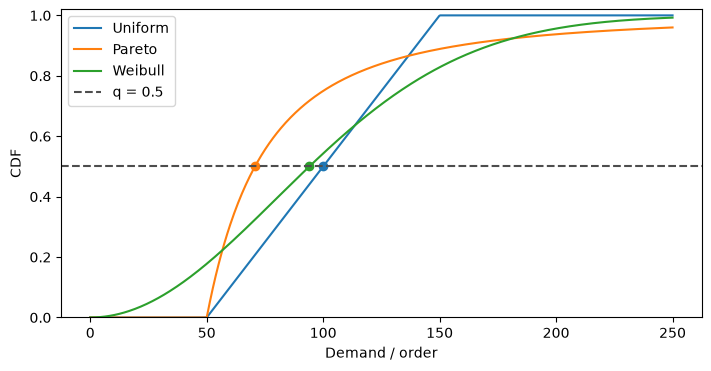

In [14]:
critical_fractile = (p - c) / (p + h)
population_orders = pd.Series({name: law.ppf(critical_fractile) for name, law in distributions.items()},
                              name='Population-optimal order')
display(population_orders.round(6).to_frame())
grid = np.linspace(0, 250, 600)
fig, ax = plt.subplots(figsize=(7, 3.6), layout='constrained')
for name, law in distributions.items():
    line, = ax.plot(grid, law.cdf(grid), label=name)
    ax.plot(population_orders[name], critical_fractile, 'o', color=line.get_color())
ax.axhline(critical_fractile, color='0.3', linestyle='--', label=f'q = {critical_fractile:g}')
ax.set(xlabel='Demand / order', ylabel='CDF', ylim=(0, 1.02))
ax.legend()
plt.show()

The critical ratio is $1/2$, so a median is optimal. The orders are
$100$, $50\sqrt{2}\approx70.710678$ and
$113\sqrt{\log 2}\approx94.078671$.

**(b)** Solve the deterministic LP for each distribution, setting demand
to its population mean. The uniform and Pareto means are 100. The Weibull
mean is $113\Gamma(3/2)\approx100.1436426$.

Complete the two recourse constraints in `newsvendor_model`. For a single
deterministic demand, pass a one-element array. Use `fixed_order` to fix an
order when you evaluate it in (c).

In [15]:
def newsvendor_model(sample, fixed_order=None):
    sample = np.asarray(sample, dtype=float)
    if sample.ndim != 1 or not len(sample) or np.any(~np.isfinite(sample)) or np.any(sample < 0):
        raise ValueError('Supply a nonempty vector of nonnegative demands.')
    m = pyo.ConcreteModel('Newsvendor')
    m.SCENARIOS = pyo.RangeSet(0, len(sample) - 1)
    m.x = pyo.Var(domain=pyo.NonNegativeReals)
    if fixed_order is not None:
        if not np.isfinite(fixed_order) or fixed_order < 0:
            raise ValueError('The fixed order must be nonnegative.')
        m.x.fix(float(fixed_order))
    m.y = pyo.Var(m.SCENARIOS, domain=pyo.NonNegativeReals)
    m.z = pyo.Var(m.SCENARIOS, domain=pyo.NonNegativeReals)

    # BEGIN NEWSVENDOR ROWS
    m.demand_limit = pyo.Constraint(m.SCENARIOS, rule=lambda m, s: m.y[s] <= sample[s])
    m.balance = pyo.Constraint(m.SCENARIOS, rule=lambda m, s: m.y[s] + m.z[s] == m.x)
    # END NEWSVENDOR ROWS

    m.total_expected_profit = pyo.Objective(
        expr=-c * m.x + sum(p * m.y[s] - h * m.z[s] for s in m.SCENARIOS) / len(sample),
        sense=pyo.maximize,
    )
    return m

In [16]:
ev_orders = pd.Series({name: law.mean() for name, law in distributions.items()}, name='EV order')
newsvendor_ev_models = {}
for name, order in ev_orders.items():
    model = newsvendor_model([order])
    solve_and_load(model, lp_solver)
    newsvendor_ev_models[name] = model
display(pd.DataFrame({'Demand mean': ev_orders,
    'Deterministic optimal order': {name: pyo.value(m.x) for name, m in newsvendor_ev_models.items()},
    'Deterministic profit (€)': {name: pyo.value(m.total_expected_profit) for name, m in newsvendor_ev_models.items()},
}).round(6))

,Demand mean,Deterministic optimal order,Deterministic profit (€)
Uniform,100.000000,100.000000,1500.000000
Pareto,100.000000,100.000000,1500.000000
Weibull,100.143643,100.143643,1502.154639


For deterministic demand $\bar z$, each extra ton ordered up to $\bar z$
earns $p-c>0$. Each ton ordered above $\bar z$ costs $c+h>0$. The EV order
is therefore $\bar z$, with deterministic profit $15\bar z$. Part (c)
evaluates that order under sampled demand.

**(c)** Use the extensive form to evaluate each EV order from (b) on the
3,000 draws for its distribution. Report its mean profit on that sample.
The next cell reproduces the draws for L8's slide *Convergence of SAA: the
practice* using root seed 2026 and a separate stream for each distribution.
Keep the arrays for (d) and (e).

In [17]:
N_NEWS = 3000
news_seeds = np.random.SeedSequence(2026).spawn(3)
news_rngs = [np.random.default_rng(seed) for seed in news_seeds]
training_samples = {
    'Uniform': news_rngs[0].uniform(50, 150, N_NEWS),
    'Pareto': 50 * (news_rngs[1].pareto(2, N_NEWS) + 1),
    'Weibull': 113 * news_rngs[2].weibull(2, N_NEWS),
}

In [18]:
newsvendor_fixed_models = {}
fixed_training_profits = {}
for name, sample in training_samples.items():
    model = newsvendor_model(sample, fixed_order=ev_orders[name])
    solve_and_load(model, lp_solver)
    newsvendor_fixed_models[name] = model
    fixed_training_profits[name] = pyo.value(model.total_expected_profit)
display(pd.DataFrame({'EV order': ev_orders, 'Sample profit of EV order (€)': fixed_training_profits}).round(4))

,EV order,Sample profit of EV order (€)
Uniform,100.0000,1116.5351
Pareto,100.0000,748.7759
Weibull,100.1436,860.3027


**(d)** Optimize the order on each sample from (c). Report the order and
how much mean profit it gains over the population-mean EV order on the same
observations. Explain why the gain is nonnegative. Give the two central
order statistics of each sample and locate the optimized order relative
to them.

In [19]:
newsvendor_saa_models = {}
newsvendor_training_rows = []
for name, sample in training_samples.items():
    model = newsvendor_model(sample)
    solve_and_load(model, lp_solver)
    newsvendor_saa_models[name] = model
    ordered = np.sort(sample)
    low, high = ordered[len(sample) // 2 - 1:len(sample) // 2 + 1]
    optimum = pyo.value(model.total_expected_profit)
    newsvendor_training_rows.append({'Distribution': name, 'SAA order': pyo.value(model.x),
        'Median interval, low': low, 'Median interval, high': high,
        'SAA sample profit (€)': optimum, 'EV order sample profit (€)': fixed_training_profits[name],
        'Sample profit gain (€)': optimum - fixed_training_profits[name]})
newsvendor_training = pd.DataFrame(newsvendor_training_rows).set_index('Distribution')
display(newsvendor_training.round(4))

,SAA order,"Median interval, low","Median interval, high",SAA sample profit (€),EV order sample profit (€),Sample profit gain (€)
Distribution,,,,,,
Uniform,99.3045,99.2990,99.3045,1116.6155,1116.5351,0.0805
Pareto,70.1421,70.1357,70.1421,878.7594,748.7759,129.9835
Weibull,93.2471,93.2471,93.2844,865.4748,860.3027,5.1721


The sample-profit objective is flat between the two central order
statistics, so every order in that interval is optimal. NumPy's median
returns the midpoint. HiGHS may return another point in the interval.

The population-mean EV order is feasible in the same sample problem, so
the gain is nonnegative. The EV order for the empirical distribution
would use the sample mean.

**(e)** Reproduce L8's SAA convergence plot. For $n=25,50,\ldots,3000$,
use the first $n$ observations from each retained array. The critical ratio
is $1/2$, so an empirical median gives an optimal order for each prefix.

Plot the orders against $n$ and mark the exact orders from (a) with
horizontal dashed lines. Give the absolute order error for each distribution
at $n=3000$. Do the errors decrease at every step? Relate the trajectories
to the convergence statement in L8.

In [20]:
sample_sizes = np.arange(25, N_NEWS + 1, 25)
# Use the first n observations of each retained sample.

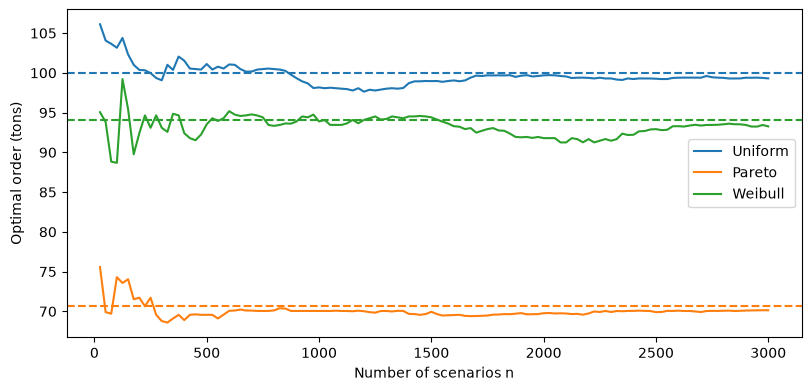

,SAA order at n=3000,Analytical optimum,Absolute order error
Uniform,99.301743,100.000000,0.698257
Pareto,70.138912,70.710678,0.571766
Weibull,93.265779,94.078671,0.812892


In [21]:
saa_paths = pd.DataFrame({
    name: [np.median(sample[:n]) for n in sample_sizes]
    for name, sample in training_samples.items()
}, index=pd.Index(sample_sizes, name='Sample size n'))
fig, ax = plt.subplots(figsize=(8, 3.8), layout='constrained')
for name in saa_paths:
    line, = ax.plot(saa_paths.index, saa_paths[name], label=name)
    ax.axhline(population_orders[name], color=line.get_color(), linestyle='--')
ax.set(xlabel='Number of scenarios n', ylabel='Optimal order (tons)')
ax.legend()
plt.show()
final_order_errors = (saa_paths.iloc[-1] - population_orders).abs()
display(pd.DataFrame({'SAA order at n=3000': saa_paths.iloc[-1],
                      'Analytical optimum': population_orders,
                      'Absolute order error': final_order_errors}).round(6))

The dashed lines mark the exact optimal orders $100$, $50\sqrt2$ and
$113\sqrt{\log2}$. The errors fluctuate. A larger prefix can move the
empirical median farther from its population value even though the sequence
converges. For even sample sizes, the plot uses the midpoint of the
interval of optimal orders.

## Exercise 3: airline seat allocation

Use the formulation in **Sheet 4 Exercise 3(a)**. The plane has space for
200 economy seats. A first-class seat takes the space of two economy seats,
and a business-class seat takes the space of 1.5. Ticket revenues are 3, 2
and 1 times the economy fare for first, business and economy, respectively.

The three demand scenarios are equally likely.

| Scenario | First | Business | Economy |
|:---|---:|---:|---:|
| Morning and evening | 20 | 50 | 200 |
| Weekend | 10 | 25 | 175 |
| Midday | 5 | 10 | 150 |

Choose integer seat counts $x_c$ before observing demand. Tickets are sold
within each class. For fixed seats and integer demand $\xi_{c,s}$, positive
ticket revenue makes optimal sales equal to $\min(x_c,\xi_{c,s})$, so the
ticket-sale variables can be continuous.

The [MO-book aircraft notebook](https://mobook.github.io/MO-book/notebooks/10/01-aircraft-seat-allocation.html)
develops the model in stages. For this lab, use the demand table above and
the forecasts specified in (b) and (c).

**(a)** Complete and solve `aircraft_stochastic`. Use one constraint for
total space and maximize the average scenario revenue. Report the
allocation, tickets sold, unused seats, unmet demand and expected revenue.

In [22]:
CLASSES = ['F', 'B', 'E']
demand = pd.DataFrame([[20, 50, 200], [10, 25, 175], [5, 10, 150]],
    columns=CLASSES, index=['Morning/evening', 'Weekend', 'Midday'])
capacity = 200
revenue_factor = pd.Series({'F': 3.0, 'B': 2.0, 'E': 1.0})
seat_factor = pd.Series({'F': 2.0, 'B': 1.5, 'E': 1.0})


def integer_demand(data):
    values = data.loc[:, CLASSES].to_numpy(dtype=float)
    if (not len(values) or np.any(~np.isfinite(values)) or np.any(values < 0)
            or not np.allclose(values, np.rint(values), rtol=0, atol=1e-8)):
        raise ValueError('The airline model requires nonnegative integer demands.')
    return pd.DataFrame(np.rint(values).astype(int), columns=CLASSES, index=data.index)


def installed_seats(model):
    raw = np.array([pyo.value(model.seats[c]) for c in CLASSES])
    if not np.allclose(raw, np.rint(raw), rtol=0, atol=1e-6):
        raise ValueError('The solution has noninteger seat counts.')
    return pd.Series(np.rint(raw).astype(int), index=CLASSES, name='Installed seats')


def airline_outcomes(seats, data):
    data = integer_demand(data)
    seats = pd.Series(seats).reindex(CLASSES)
    if (seats.isna().any() or (seats < 0).any()
            or not np.allclose(seats, np.rint(seats), rtol=0, atol=1e-8)
            or seats.dot(seat_factor) > capacity + 1e-7):
        raise ValueError('Supply a feasible integer seat allocation.')
    tickets = data.clip(upper=seats, axis=1)
    first_failure = data['F'] > seats['F']
    combined_failure = data['F'] + data['B'] > seats['F'] + seats['B']
    return {'tickets': tickets, 'unused': seats - tickets, 'spillage': data - tickets,
            'revenue': tickets.dot(revenue_factor), 'first_failure': first_failure,
            'combined_failure': combined_failure, 'joint_failure': first_failure | combined_failure}


def seat_report(seats, data):
    outcomes = airline_outcomes(seats, data)
    display(pd.DataFrame({'Installed seats': seats,
                          'Economy-equivalent space': seats * seat_factor}))
    print(f'Total space: {seats.dot(seat_factor):g} / {capacity}')
    if len(data) <= 10:
        for key, label in [('tickets', 'Tickets sold'), ('unused', 'Unused seats'), ('spillage', 'Unmet demand')]:
            print(label)
            display(outcomes[key])
    else:
        display(pd.DataFrame({key: outcomes[key].mean() for key in ['tickets', 'unused', 'spillage']}).round(3))
    print(f'Mean revenue: {outcomes["revenue"].mean():.3f} economy-ticket units')
    return outcomes

In [23]:
def aircraft_stochastic(data):
    data = integer_demand(data)
    if not data.index.is_unique:
        raise ValueError('Scenario labels must be unique.')
    m = pyo.ConcreteModel('Aircraft seat allocation')
    m.CLASSES = pyo.Set(initialize=CLASSES)
    m.SCENARIOS = pyo.Set(initialize=data.index)
    m.seats = pyo.Var(m.CLASSES, domain=pyo.NonNegativeIntegers)
    m.tickets = pyo.Var(m.CLASSES, m.SCENARIOS, domain=pyo.NonNegativeReals)

    # BEGIN AIRCRAFT ROWS
    m.plane_seats = pyo.Constraint(expr=sum(seat_factor[c] * m.seats[c] for c in CLASSES) <= capacity)
    m.demand_limits = pyo.Constraint(m.CLASSES, m.SCENARIOS,
        rule=lambda m, c, s: m.tickets[c, s] <= int(data.loc[s, c]))
    m.seat_limits = pyo.Constraint(m.CLASSES, m.SCENARIOS,
        rule=lambda m, c, s: m.tickets[c, s] <= m.seats[c])
    # END AIRCRAFT ROWS

    m.revenue = pyo.Objective(
        expr=sum(revenue_factor[c] * m.tickets[c, s] for c in CLASSES for s in m.SCENARIOS) / len(data),
        sense=pyo.maximize,
    )
    return m

,Installed seats,Economy-equivalent space
F,10,20.0
B,20,30.0
E,150,150.0


Total space: 200 / 200
Tickets sold


,F,B,E
Morning/evening,10,20,150
Weekend,10,20,150
Midday,5,10,150


Unused seats


,F,B,E
Morning/evening,0,0,0
Weekend,0,0,0
Midday,5,10,0


Unmet demand


,F,B,E
Morning/evening,10,30,50
Weekend,0,5,25
Midday,0,0,0


Mean revenue: 208.333 economy-ticket units


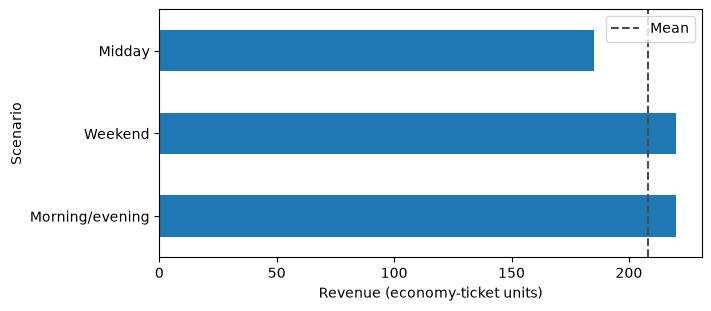

In [24]:
aircraft_rp = aircraft_stochastic(demand)
solve_and_load(aircraft_rp, lp_solver)
seats_rp = installed_seats(aircraft_rp)
airline_a_outcomes = seat_report(seats_rp, demand)
fig, ax = plt.subplots(figsize=(7, 3), layout='constrained')
airline_a_outcomes['revenue'].plot.barh(ax=ax)
ax.axvline(airline_a_outcomes['revenue'].mean(), color='0.3', linestyle='--', label='Mean')
ax.set(xlabel='Revenue (economy-ticket units)', ylabel='Scenario')
ax.legend()
plt.show()

The allocation is $(10,20,150)$ with mean revenue $625/3\approx208.333$.
The three scenario revenues are 220, 220 and 185. The shared seat allocation
is nonanticipative; ticket sales respond to the scenario. Averaging, rather
than summing, makes the objective agree with the reported mean revenue.

**(b)** Require first-class demand to fit in first-class seats with
probability at least 98%, and combined first- and business-class demand to
fit in their combined seats with probability at least 95%.

Use the independent Gaussian forecasts in **Sheet 4 Exercise 5(a)**,
denoted here by $\eta_F\sim\mathcal N(16,16)$ and
$\eta_B\sim\mathcal N(30,48)$. The second parameter is the variance. The
equivalent capacity bounds are

$$
x_F\ge16+\Phi^{-1}(0.98)\sqrt{16},\qquad
x_F+x_B\ge46+\Phi^{-1}(0.95)\sqrt{64}.
$$

For integer seats these become $x_F\ge25$ and $x_F+x_B\ge60$. Add the bounds
to your model in (a) and keep its three scenarios for calculating revenue.
Explain the changes in allocation and revenue. Ticket sales still use
the own-class limits in (a).

In [25]:
sheet_mean = np.array([16.0, 30.0])
sheet_covariance = np.diag([16.0, 48.0])

In [26]:
def gaussian_capacity_bounds(mean, covariance, first_level=0.98, combined_level=0.95):
    if not (0 < first_level < 1 and 0 < combined_level < 1):
        raise ValueError('Capacity probabilities must lie strictly between zero and one.')
    first = mean[0] + norm.ppf(first_level) * np.sqrt(covariance[0, 0])
    combined_variance = covariance[0, 0] + covariance[1, 1] + 2 * covariance[0, 1]
    combined = mean[0] + mean[1] + norm.ppf(combined_level) * np.sqrt(combined_variance)
    return float(first), float(combined)


def aircraft_cc(data, mean, covariance, first_level=0.98, combined_level=0.95):
    m = aircraft_stochastic(data)
    first, combined = gaussian_capacity_bounds(mean, covariance, first_level, combined_level)
    m.first_capacity = pyo.Constraint(expr=m.seats['F'] >= first)
    m.combined_capacity = pyo.Constraint(expr=m.seats['F'] + m.seats['B'] >= combined)
    return m


aircraft_sheet_cc = aircraft_cc(demand, sheet_mean, sheet_covariance)
solve_and_load(aircraft_sheet_cc, lp_solver)
seats_sheet_cc = installed_seats(aircraft_sheet_cc)
airline_b_outcomes = seat_report(seats_sheet_cc, demand)

,Installed seats,Economy-equivalent space
F,25,50.0
B,35,52.5
E,97,97.0


Total space: 199.5 / 200
Tickets sold


,F,B,E
Morning/evening,20,35,97
Weekend,10,25,97
Midday,5,10,97


Unused seats


,F,B,E
Morning/evening,5,0,0
Weekend,15,10,0
Midday,20,25,0


Unmet demand


,F,B,E
Morning/evening,0,15,103
Weekend,0,0,78
Midday,0,0,53


Mean revenue: 178.667 economy-ticket units


The allocation is $(25,35,97)$ and mean revenue is $536/3\approx178.667$.
The capacity targets reserve more space for premium classes, leaving fewer
economy seats. In the low-demand scenarios some premium seats are unused.
The forecast used for these targets is separate from the three scenarios
used to calculate revenue.

**(c)** Now use the forecast from L8's *Seat allocation: correlated
nonnegative demand* slide. In first/business/economy order, the latent
vector $\eta$ is Gaussian with mean and covariance

$$
\mu=(12,28,175),\qquad
\Sigma=\begin{pmatrix}3.5&3.7&2.5\\3.7&6.5&7.5\\2.5&7.5&25.2\end{pmatrix}.
$$

L8 clips demand at zero, $z_c=\max(\eta_c,0)$. For ticket counts the lab
also rounds down, $\xi_c=\lfloor z_c\rfloor$. Use the supplied count sample
obtained from the 1,000 latent draws used for the figure.

Derive the 98% bound for $\eta_F$ and the 95% bound for $\eta_F+\eta_B$.
Include covariance in the combined variance, as in Sheet 4 Exercise 5(d).
Impose the resulting bounds on the seats and maximize average ticket revenue
over the integer count scenarios.

In [27]:
airline_mean = np.array([12.0, 28.0, 175.0])
airline_covariance = np.array([[3.5, 3.7, 2.5], [3.7, 6.5, 7.5], [2.5, 7.5, 25.2]])


def sample_airline(size, seed):
    latent = np.random.default_rng(seed).multivariate_normal(
        airline_mean, airline_covariance, size, method='cholesky')
    counts = np.floor(np.maximum(latent, 0)).astype(int)
    return pd.DataFrame(counts, columns=CLASSES)

In [28]:
#@title Load the fixed airline count sample
from base64 import b64decode
from zlib import decompress

_lecture_payload = (
    'eNpVWMl220YQnJNNYiNzsESslOz8t/1iSSRAAAQILpKdl0O+LNPVNQPmgoc3GPT0Ul3dPbEpTGsSszVnE5vSjCYy'
    'uelMaN9P9pmbg10pzGT3VOZoArv+j10pzWAW5sG82j0b82KWJrP75Sl7Mvs1tH/1VmZhJcRW/smub+z78u5rZGWe'
    'cVaH01v7rCinwelySmplynsNab19l6+RlXnEv/JMedYR/3Y4683uybBf/grsns58sut72FtDqzOsG2mRSJu8FanZ'
    'wZYWElqsH3DKZFecx3r6TfzTQJr6rbcrT+aK9TNWWmj13b5X2CO6fTZf7PoKO8WTnT1FvSr+X5hHa0UAi0KcEkLb'
    'EBrK+4CvJ7xf7L8au1lb1WRlvtqvMU9RaSk8kyMuotuCp4u3JS49bBzt+hfzA3vUugN8daRFsvMCaQ39nNivDfWP'
    'iCLxpFjXQM4JpwxWq2erj1vJ4X/FRmqjIzG6IMoNYtFD2oWYFJwM9LDsV4xN0LABhgUJGyDKxXpgLOTfEfrsIHOC'
    'zD3/DYiEwnpjAQmJ1fNIJC+gm0peAQMJpEXAnuoWwFI55QDN33higBiteLr4M/HIbBgLkdbirDd44w3rnZdf0caO'
    'T8X8Cl6S9z38eca/NfYPOLezSBNciccm+EeRfEWkrsiUBj6fzB92zwVfJS6FuXmcaJZlNt8l7qJDShvVVzXQeIa0'
    'nWcAydwI6BVMvsIDByJKTv+ALS3+baycDF9FkwAIl7MUJ3v7ryAqZo6L7RodRZTiMKaEjDg5QZ/vwH9P5IgHNGq6'
    '0tHShB5Te5UZtmChDXF7BnLesDLCdpfLM8t1kNkigwZ6VXUTnE/wzAlf/2V2r82f5h2+emWmKw8Lt+xxboNTJsSl'
    'hoY9M10zN4DMCHHXLFa0q3xdCaCnPiPvpQvlOx8+2YgkYFflkAR4EC5S/6uvJti+B6OO5OQE2eQ4QXFbEm/q8xPf'
    '9WuCnUvorzsVnzGR8Mg8+kWrI9gSWSTvIeHIPNJclv019k/Eqq6E9KRgb23lD/R/gMol+HlnLRDPq/ckso/0z+jz'
    '/QnssQV3belP5Y0BvDERUWLFDZpcEdMWcW/gmRNZVHj+jZkVg2kDXz2V56/wVY3MfSGKIjJVxppSs0oKtn/52l1B'
    'h2ecJVX7s7WoBWZurHRLa91fZP6YMU3Bfo/WSxE5XGvNMyQr2zwBUcrDFXE+MIIJ7JVYvDLWAat8ia9bVqsR9vZ3'
    '1a3xdVw9mbLKCFYfYG/JDHoh6iLU5Zg1Ua12cgZapJym0dTK4qxwyFQ0fsCuG5jnDM9oR3TA1519l+qZQLJqIvq/'
    'WeRL7V7DzyEyImJW5ug9SjKnRvPGSDns5cisAtpqVcrgf7UrA2Ye0IHk+HcDG3PGvfdWF8jWErUjBzILyjl4yRV8'
    'myE7MjLDlewtci7I9HdWwJAdV8EKVePfA6tGAhbVDiSGpeKBM/a7rkD2/Mae1tf9En6uzN9Wzgb5m7ED7LnH8fwj'
    'tJKaskK8Aq/nAfwzop/5TW2XqKoB6vKcOztU6j37ooA2Ct4kL5QzG2jeIr43ZrHW2dl7E6uJYjiEP5UNQtji0JXz'
    '9JM/t4L+FXqknD3kGesjNRcUtciRM2zXPuRGZouJ/wKRfcbXyvpQmW0F5hcvffcoKu46tML3AzNP9mChM3TuoZV2'
    '79pvjIja6NFVsNY3wGENtlRu3MNvPfQR31bMOO3BjtB57jNzWnok/iNUHNfzpPTMCRGZ2HcFsC62p3wAq3v21Stf'
    'SVvgpCWb6ewg+tyY10sw/xpfE/YbJTi5YAYdPAMUjOwHZO6g+Y5Y0noqEnT66NAP/CYbLxDxiL1KaXlSMvEFmVhz'
    '0pGdWl+0vu/Ija6/Sjm/tMBVDc8M7LEl7iP945jHMaTrfzSLF/SJoHqFDI2Qm1rH16g7CTAZ+uxrfZ+TQU7BHO/v'
    'OOpImeKxn/jagC2FD3U+StlLN8yLOY9OxJ6sD0R4wJqVsu9t4bGOXZOs//Tdvva6W8jZIMobdJ6qZwUfVr4/DKGJ'
    'VtWAqE7h7YLdSEs2Xptv6CiesJ6xi65ZOwI/8+6QWQ07ap0TA/pNZqKQeHAs98L+Z57Ojqhxr6x9IXJnxXNzP3er'
    'VitEJyA2St+lB8yRnB3gFadcoY9k4pbR7DhxxOy+BMNu+lYsfYWXHH5GxjpBR7Gk/7V7qdiTTPh3IGsFnObmuSPG'
    'SkCGSVHZyzsvbYDAkhy4B//0QOxIfH7yXdBEtgzRU2mfHDG+W3J4d9dbnqCzzmU67fb+hkFyX7hC97vpzO3Jmdc/'
    'WZe1dkScvHL2Qh08cOV9QoQOU07ssTLXxG+oRE+M2js5xNXKijn+g7U4Ag9EnpN37By015pnpR46n/1dikPvkTOj'
    'zoYRe7+vthLpFLMGZyobJ8RwyVl1ZK6FrKcVu9kb71Vcl1XQYyfeRaxQ3xPe0uhUrrZnZM4ruT3g5FKQf05+Vs2I'
    'KO2yRrJK5Hn4glMmb6/efjywC+3YCc84P0HOOzzcs/LObFbja88uIvBss/f1tPIdnbspcvczc7fpbjBadOCtz8Qn'
    'TrIX8rmy2RKY1+l+yTqSUtqFk2zAiT7lBDcQvTHrdU4Nj/DGBVFz3ezKx/QIf86TwsZ28jHql97RzTdRA9lGewmn'
    'T+H71Ri5lngdOtYpN0drpjg+ObL/dEgu6G2dcy/USuvLwueau1dZoF67zrwg5++YC4lnqpFsMN9rudlhjbom2eRm'
    'TPVSyKzJyC3KYwdma3R3Z7IAugJy0aOP+8wqPWcxt17czQI6uVS8M5nItFqRl5hVl5jQtbsIcfMTMSMyVna9aTz7'
    'ie+R3Fv7+UX6+SVx6Lx0QrUaPAcW7MRaMoDeRC2Yg1rNS8aoZ67pjUHwv5uZClGryOSK+QNtd9ye4f6qgOd1sqvo'
    'nzN7eK22n8HGrpvasg62YLyRORvydOVbd/eomjSoBR3vDyN24O5Ob/A30qqPzPKu1iiqU5sFiZ/pdO6rfdS2qJji'
    'JcmIjh1UzMoitTskh4jnY856BeZ37dxK9Htf/A1SQv0VwxkyN2O3uaP+S5+tBzDz0fwH8eJB2g=='
)
_lecture_bytes = decompress(b64decode(_lecture_payload))
if hashlib.sha256(_lecture_bytes).hexdigest() != '1d67fa2e749b9a544cadc7199d6c30445d531876dbb009941ad70f262d1ed765':
    raise RuntimeError('The embedded lecture sample failed its integrity check.')
demand_saa = pd.DataFrame(np.frombuffer(_lecture_bytes, dtype='<u2').reshape(1000, 3).astype(int),
                          columns=CLASSES)
del _lecture_payload, _lecture_bytes

,Latent mean,Count sample mean,Latent standard deviation,Count sample standard deviation
F,12.0,11.496,1.871,1.805
B,28.0,27.556,2.550,2.517
E,175.0,174.368,5.020,5.059


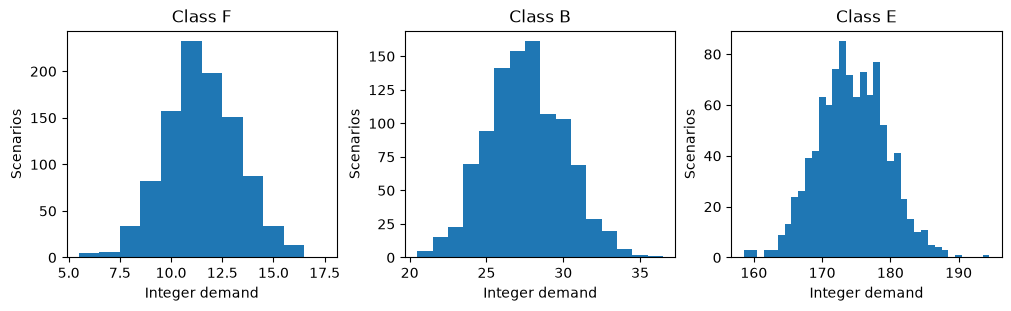

In [29]:
display(pd.DataFrame({'Latent mean': airline_mean, 'Count sample mean': demand_saa.mean(),
                      'Latent standard deviation': np.sqrt(np.diag(airline_covariance)),
                      'Count sample standard deviation': demand_saa.std()}, index=CLASSES).round(3))
fig, axes = plt.subplots(1, 3, figsize=(10, 3), layout='constrained')
for ax, cls in zip(axes, CLASSES):
    ax.hist(demand_saa[cls], bins=np.arange(demand_saa[cls].min() - 0.5, demand_saa[cls].max() + 1.5))
    ax.set(title=f'Class {cls}', xlabel='Integer demand', ylabel='Scenarios')
plt.show()

Latent Gaussian bounds: [15.842212 46.861228]
Integer capacity bounds: (16, 47)


,Installed seats,Economy-equivalent space
F,16,32.0
B,31,46.5
E,121,121.0


Total space: 199.5 / 200


,tickets,unused,spillage
F,11.495,4.505,0.001
B,27.456,3.544,0.100
E,121.000,0.000,53.368


Mean revenue: 210.397 economy-ticket units


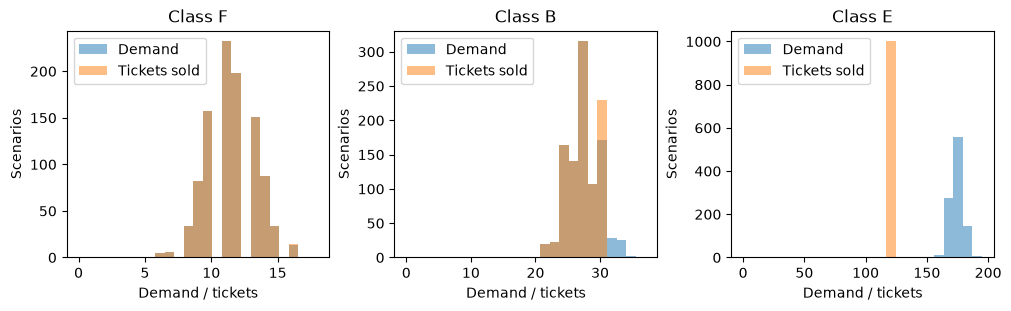

In [30]:
latent_bounds = gaussian_capacity_bounds(airline_mean, airline_covariance)
print('Latent Gaussian bounds:', np.round(latent_bounds, 6))
print('Integer capacity bounds:', tuple(math.ceil(v) for v in latent_bounds))
aircraft_gaussian = aircraft_cc(demand_saa, airline_mean, airline_covariance)
solve_and_load(aircraft_gaussian, lp_solver)
seats_gaussian = installed_seats(aircraft_gaussian)
airline_c_outcomes = seat_report(seats_gaussian, demand_saa)

fig, axes = plt.subplots(1, 3, figsize=(10, 3), layout='constrained')
for ax, cls in zip(axes, CLASSES):
    upper = max(demand_saa[cls].max(), seats_gaussian[cls])
    bins = np.linspace(0, max(1, upper) + 1, 26)
    ax.hist(demand_saa[cls], bins=bins, alpha=0.5, label='Demand')
    ax.hist(airline_c_outcomes['tickets'][cls], bins=bins, alpha=0.5, label='Tickets sold')
    ax.set(title=f'Class {cls}', xlabel='Demand / tickets', ylabel='Scenarios')
    ax.legend()
plt.show()

The latent first-class and combined bounds are approximately 15.842212 and
46.861228, giving integer bounds 16 and 47. The combined variance is
$3.5+6.5+2(3.7)=17.4$. On the 1,000 count scenarios, the allocation is
$(16,31,121)$ and mean revenue is 210.397 in units of the economy fare.

The Gaussian formulas apply to $\eta_F$ and $\eta_F+\eta_B$. Exercise 4(c)
counts successes for $\xi_F$ and $\xi_F+\xi_B$. For example, $\xi_F\le16$
is equivalent to $\eta_F<17$, which has probability about 0.99624.
Rounding down weakly reduces each demand after clipping. Clipping can
increase the combined demand relative to the latent sum only if a premium
component is negative, an event of probability at most $7.1\times10^{-11}$
under this forecast.

For fixed seats, $\mathbb E Q(x,\xi)=\sum_c r_c\mathbb E\min(x_c,\xi_c)$,
where $r_c$ is the fare for class $c$. Only the marginal laws enter that
population objective. The combined capacity target depends on the distribution
of the sum and thus on the dependence between the demands.

## Exercise 4: a sampled joint capacity target

Use the first $N=500$ count scenarios from 3(c), with weight $1/N$ each.
Let $\widehat{\mathbb P}_N$ denote probability under that sample. Require
both capacity inequalities to hold in at least 95% of the scenarios.

$$
\widehat{\mathbb P}_N(\xi_F\le x_F,\ \xi_F+\xi_B\le x_F+x_B)\ge0.95.
$$

The [book's aircraft Model 6](https://mobook.github.io/MO-book/notebooks/10/01-aircraft-seat-allocation.html#model-6-tackling-chance-constraints-using-saa-in-the-case-of-correlated-demand)
uses separate budgets for its individual targets. For a joint target, use
one indicator per scenario, as in L7 and the book's
[economic dispatch model](https://mobook.github.io/MO-book/notebooks/09/04-economic-dispatch.html).

**(a)** Formulate the joint constraint with a binary variable $u_s$ for
each scenario, where $u_s=1$ permits a violation of either capacity row.
Derive the smallest valid big-$M$ constant for each row and scenario over
the original seat domain. Give the integer violation budget for
$\varepsilon=0.05$ and $N=500$.

**(b)** Add the joint constraint to `aircraft_stochastic` without the Gaussian
bounds. Report the optimal allocation, average revenue, number of
permissions and actual first-class, combined and joint failure counts.
Keep the ticket-sale constraints and the revenue contribution for every
scenario, including those with $u_s=1$.

**(c)** Use the same 500 scenarios for all four models. Solve the
unrestricted model, the model with the latent Gaussian bounds from 3(c)
and the supplied `aircraft_individual` model. It enforces individual 98%
and 95% targets on the counts, with budgets of 10 and 25 scenarios.
Include the joint model from (b).

Report average revenue and coverage for the first-class, combined and joint
events under each allocation. How much of the revenue difference between
the latent Gaussian and sampled joint models is already present under the
sampled individual targets? If the last two models return the same optimal
allocation, does that establish equality of their feasible sets? Relate your
answer to Sheet 4 Exercise 4(d).

In [31]:
joint_training = demand_saa.iloc[:500].copy()
epsilon = 0.05

In [32]:
def aircraft_individual(data, first_level=0.98, combined_level=0.95):
    if not (0 <= first_level <= 1 and 0 <= combined_level <= 1):
        raise ValueError('Capacity probabilities must lie in [0, 1].')
    data = integer_demand(data)
    m = aircraft_stochastic(data)
    m.first_permission = pyo.Var(m.SCENARIOS, domain=pyo.Binary)
    m.combined_permission = pyo.Var(m.SCENARIOS, domain=pyo.Binary)
    # A success target q requires at least ceil(q*N) successful scenarios.
    first_budget = len(data) - math.ceil(first_level * len(data))
    combined_budget = len(data) - math.ceil(combined_level * len(data))
    m.first_budget = pyo.Param(initialize=first_budget)
    m.combined_budget = pyo.Param(initialize=combined_budget)

    @m.Constraint(m.SCENARIOS)
    def individual_first(m, s):
        first = int(data.loc[s, 'F'])
        return m.seats['F'] + first * m.first_permission[s] >= first

    @m.Constraint(m.SCENARIOS)
    def individual_combined(m, s):
        combined = int(data.loc[s, 'F'] + data.loc[s, 'B'])
        return m.seats['F'] + m.seats['B'] + combined * m.combined_permission[s] >= combined

    m.first_permission_limit = pyo.Constraint(
        expr=sum(m.first_permission[s] for s in m.SCENARIOS) <= m.first_budget)
    m.combined_permission_limit = pyo.Constraint(
        expr=sum(m.combined_permission[s] for s in m.SCENARIOS) <= m.combined_budget)
    return m

### Solution to 4(a)

Use $M_{F,s}=\xi_{F,s}$ and $M_{FB,s}=\xi_{F,s}+\xi_{B,s}$:

$$
\begin{aligned}
x_F+M_{F,s}u_s&\ge \xi_{F,s} &&\forall s,\\
x_F+x_B+M_{FB,s}u_s&\ge \xi_{F,s}+\xi_{B,s} &&\forall s,\\
\sum_s u_s&\le\lfloor\varepsilon N\rfloor=25,\qquad u_s\in\{0,1\}.
\end{aligned}
$$

Both rows are enforced when $u_s=0$. When $u_s=1$, the lower bound becomes
zero. Since the original domain permits $x_F=x_B=0$, smaller constants
would fail to deactivate their rows there. A permission need not be used,
so its count can exceed the number of actual failures.

In [33]:
def aircraft_joint(data, epsilon=0.05):
    if not 0 <= epsilon <= 1:
        raise ValueError('epsilon must lie in [0, 1].')
    data = integer_demand(data)
    m = aircraft_stochastic(data)
    m.u = pyo.Var(m.SCENARIOS, domain=pyo.Binary)
    m.violation_budget = pyo.Param(initialize=math.floor(epsilon * len(data)))

    # BEGIN JOINT ROWS
    @m.Constraint(m.SCENARIOS)
    def joint_first(m, s):
        first = int(data.loc[s, 'F'])
        return m.seats['F'] + first * m.u[s] >= first

    @m.Constraint(m.SCENARIOS)
    def joint_combined(m, s):
        combined = int(data.loc[s, 'F'] + data.loc[s, 'B'])
        return m.seats['F'] + m.seats['B'] + combined * m.u[s] >= combined

    m.permission_limit = pyo.Constraint(expr=sum(m.u[s] for s in m.SCENARIOS) <= m.violation_budget)
    # END JOINT ROWS
    return m

In [34]:
aircraft_joint_model = aircraft_joint(joint_training, epsilon)
solve_and_load(aircraft_joint_model, lp_solver)
seats_joint = installed_seats(aircraft_joint_model)
joint_outcomes = seat_report(seats_joint, joint_training)
permission_count = sum(pyo.value(aircraft_joint_model.u[s]) > 0.5 for s in aircraft_joint_model.SCENARIOS)
print(f'Permissions: {permission_count} / {pyo.value(aircraft_joint_model.violation_budget)} allowed')
for key in ['first_failure', 'combined_failure', 'joint_failure']:
    print(f'{key}: {int(joint_outcomes[key].sum())} / {len(joint_training)}')

,Installed seats,Economy-equivalent space
F,15,30.0
B,31,46.5
E,123,123.0


Total space: 199.5 / 200


,tickets,unused,spillage
F,11.376,3.624,0.014
B,27.480,3.520,0.114
E,123.000,0.000,51.500


Mean revenue: 212.088 economy-ticket units
Permissions: 24 / 25 allowed
first_failure: 6 / 500
combined_failure: 19 / 500
joint_failure: 19 / 500


The allocation is $(15,31,123)$, with sample mean revenue 212.088.
There are 6 first-class failures, 19 combined failures and 19 joint failures
among 500 scenarios. Actual joint failures need only be at most the number
of permissions, which is at most 25; neither inequality must be an equality.

In [35]:
aircraft_unrestricted_500 = aircraft_stochastic(joint_training)
aircraft_gaussian_500 = aircraft_cc(joint_training, airline_mean, airline_covariance)
aircraft_individual_500 = aircraft_individual(joint_training)
for model in [aircraft_unrestricted_500, aircraft_gaussian_500, aircraft_individual_500]:
    solve_and_load(model, lp_solver)
comparison_plans = {
    'No targets': installed_seats(aircraft_unrestricted_500),
    'Latent Gaussian 98%/95%': installed_seats(aircraft_gaussian_500),
    'Sampled individual 98%/95%': installed_seats(aircraft_individual_500),
    'Sampled joint 95%': seats_joint.copy(),
}


def airline_comparison(plans, sample):
    rows = []
    for name, seats in plans.items():
        outcome = airline_outcomes(seats, sample)
        rows.append({'Policy': name, **seats.to_dict(),
            'Mean revenue': outcome['revenue'].mean(),
            'First coverage': 1 - outcome['first_failure'].mean(),
            'Combined coverage': 1 - outcome['combined_failure'].mean(),
            'Joint coverage': 1 - outcome['joint_failure'].mean(),
            'Joint failures': int(outcome['joint_failure'].sum())})
    return pd.DataFrame(rows).set_index('Policy')


airline_training_comparison = airline_comparison(comparison_plans, joint_training)
print('Sampled individual budgets:', pyo.value(aircraft_individual_500.first_budget),
      pyo.value(aircraft_individual_500.combined_budget))
print(f'Scenarios compared: {len(joint_training)}')
display(airline_training_comparison.round(4))

Sampled individual budgets: 10 25
Scenarios compared: 500


,F,B,E,Mean revenue,First coverage,Combined coverage,Joint coverage,Joint failures
Policy,,,,,,,,
No targets,11,26,139,221.674,0.556,0.352,0.344,328
Latent Gaussian 98%/95%,16,31,121,210.124,0.998,0.978,0.978,11
Sampled individual 98%/95%,15,31,123,212.088,0.988,0.962,0.962,19
Sampled joint 95%,15,31,123,212.088,0.988,0.962,0.962,19


On the 500 scenarios, the unrestricted allocation $(11,26,139)$ earns
221.674 with 328 joint failures. The allocation $(16,31,121)$ from the
latent Gaussian bounds earns 210.124 with 11 joint failures. The sampled
individual and joint models both choose $(15,31,123)$, earn 212.088
and have 19 joint failures.

At the same individual target levels, the count thresholds are
$x_F\ge15$ and $x_F+x_B\ge46$, compared with 16 and 47 under the latent
Gaussian forecast. The sampled individual model already achieves the
full revenue gain of 1.964 over the latent Gaussian model.

At $x_F=15$ and $x_F+x_B=46$, there are 19 joint failures. Increasing either
threshold cannot increase that count, so every allocation satisfying both
sampled individual targets also meets the joint target on this sample.
The allocation $(14,33,122)$ uses 199.5 units of space and has 24 joint
failures, within the budget of 25. Its 22 first-class failures exceed the
individual budget of 10. Thus the joint feasible set here is strictly
larger. Sheet 4 Exercise 4(d) uses equal levels for the joint and individual
targets. At equal levels, joint feasibility implies individual feasibility,
and the sheet gives a counterexample to the converse.

For the connection between chance constraints and VaR, see Sheet 4 Exercise
8(c), which asks you to write a probability requirement on profit as a VaR
bound.